In [ ]:
!pip install seisbench cartopy pyocto numpy matplotlib xdas

In [ ]:
# imports

import obspy
import os
from obspy.clients.fdsn import Client
from obspy import UTCDateTime
import numpy as np
import matplotlib.pyplot as plt
import torch
import pyocto
import seisbench
import seisbench.models as sbm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import math
from obspy.geodetics.base import gps2dist_azimuth
from obspy.signal.invsim import simulate_seismometer

### ML-based picking with PhaseNet

In this section we apply **PhaseNet** (Zhu and Beroza, 2019) to detect and pick earthquakes on traces downloaded from EIDA via obspy and SeisBench. We use the pre-trained model weights from the **INSTANCE** database  (Michelini et al.,2021). The model predicts P and S phase probabilities on each trace, which we then convert to discrete picks. In this example, we will download traces from 23 stations located on the Central Ionian Islands and the surrounding mainland Greece areas, for 30 minutes on March 4th, 2024, when a very productive seismic swarm was underway.

In [ ]:
# ========================
# Parameters (edit me)
# ========================
# Time window (UTC)
t0 = UTCDateTime("2024-03-04 00:00:00")
duration_minutes = 30
t1 = t0 + duration_minutes * 60

# FDSN request
FDSN_PROVIDER = "EIDA" #Alternative: NOA
networks = "HT,HL,HP,HA"
stations = "ATHR,HAVD,LKD2,FSK,VLS,LTHK,PSDA,RTZL,EVGI,ITHC,DMLN,NYDR,TSLK,RLS,DRAG,KEF3,KEF4,ORTH,VLMS,PLEV,AXS,PDO,KSTR"
location = "*"
channel = "HH?"

# PhaseNet picking parameters
BATCH_SIZE = 128
P_THRESHOLD = 0.10
S_THRESHOLD = 0.10

# Association / search area
LAT_BOUNDS = (37.5, 39.0)
LON_BOUNDS = (20.0, 22.0)
ZLIM_KM = (0.0, 100.0)
TIME_BEFORE_S = 300
N_PICKS = 12
N_P_AND_S_PICKS = 4

# Simplified velocity model (km/s)
P_VELOCITY = 6.2
S_VELOCITY = 3.3
TOLERANCE_S = 2.0
ASSOCIATION_CUTOFF_DISTANCE_KM = 150

# Set plotting style

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Outputs
SAVE_OUTPUTS = True
OUTPUT_DIR = "outputs"

In [ ]:
# ========================
#  Fetch seismic data and download waveforms
# ========================
client = Client(FDSN_PROVIDER)
try:
    stream = client.get_waveforms(
        network=networks,
        station=stations,
        location=location,
        channel=channel,
        starttime=t0,
        endtime=t1,
    )
    print(f" Downloaded {len(stream)} traces from {FDSN_PROVIDER} for {t0}–{t1}.")
except Exception as e:
    stream = obspy.Stream()
    print("Could not download waveforms from the FDSN service.")
    print("  This can happen due to temporary outages, rate limiting, or request constraints.")
    print(f"   Details: {type(e).__name__}: {e}")
    print("   Tip: try a shorter time window, fewer stations, or a different provider.")

 Downloaded 898 traces from EIDA for 2024-03-04T00:00:00.000000Z–2024-03-04T00:30:00.000000Z.


In [ ]:
# Download station metadata (inventory)
try:
    inv = client.get_stations(
        network=networks,
        station=stations,
        location=location,
        channel=channel,
        starttime=t0,
        endtime=t1,
        level="response",
    )
    print("Downloaded station inventory.")
except Exception as e:
    inv = None
    print(" Could not download station metadata (inventory) from the FDSN service.")
    print(f"   Details: {type(e).__name__}: {e}")
    print("   Without station metadata, event association + mapping will be skipped.")

Downloaded station inventory.


In [ ]:
# ========================
# Run PhaseNet picker
# ========================
#Using the backup repository to avoid server troubles
seisbench.use_backup_repository()
picker = sbm.PhaseNet.from_pretrained("instance")

2026-02-25 11:33:23,870 | seisbench | WARNING | Setting remote root to: https://seisbench.gfz.de/mirror/
Please note that this can affect your download speed.
Please note that this can affect your download speed.
Downloading: 100%|██████████| 1.06M/1.06M [00:00<00:00, 1.91MB/s]


In [ ]:
#In case you are running this example locally and you have a GPU, it will be prioritized for more efficient picking
if len(stream) == 0:
    print(" No waveforms available (download failed or returned empty). Skipping picking + association.")
else:
    if torch.cuda.is_available():
        picker.cuda()
        print("Using GPU:", torch.cuda.get_device_name(0))
    else:
        print(" Running on CPU")

 Running on CPU


In [ ]:
# Picking phases (only if we have data)
if len(stream) > 0:
    picks = picker.classify(
        stream,
        batch_size=BATCH_SIZE,
        P_threshold=P_THRESHOLD,
        S_threshold=S_THRESHOLD
    ).picks
else:
    picks = []
print(f"Total picks: {len(picks)}")

Total picks: 850


### Association step

In this section we use **Pyocto** (Münchmeyer, 2023) to associate phases into events. We use a simplified generalized velocity model for this example, and the associate_seisbench function of SeisBench.

In [ ]:
# ========================
# Association step
# ========================
velocity_model = pyocto.VelocityModel0D(
    p_velocity=P_VELOCITY,
    s_velocity=S_VELOCITY,
    tolerance=TOLERANCE_S,
    association_cutoff_distance=ASSOCIATION_CUTOFF_DISTANCE_KM,
)

In [ ]:
associator = pyocto.OctoAssociator.from_area(
    lat=LAT_BOUNDS,
    lon=LON_BOUNDS,
    zlim=ZLIM_KM,
    time_before=TIME_BEFORE_S,
    velocity_model=velocity_model,
    n_picks=N_PICKS,
    n_p_and_s_picks=N_P_AND_S_PICKS,
)

In [ ]:
# Associate picks into events
if (len(picks) == 0) or (inv is None):
    events = []
    assignments = None
    if inv is None:
        print(" Skipping association: station inventory is missing.")
    if len(picks) == 0:
        print(" Skipping association: no picks were produced.")
else:
    stations_df = associator.inventory_to_df(inv)
    events, assignments = associator.associate_seisbench(picks, stations_df)
    associator.transform_events(events)
print(f"Associated events: {len(events)}")

Associated events: 25



## Approximate Local Magnitude (ML) Estimation

This section computes an approximate local magnitude (ML) for each detected event and then produces a simple map with the associated events.

- Uses only stations that contributed associated picks
- Removes instrument response
- Simulates Wood–Anderson response
- Uses the formula proposed by Hutton and Boore (1987)


In [ ]:
# Magnitude helper functions live here


paz_wa = {
    "poles": [-6.283 + 4.7124j, -6.283 - 4.7124j],
    "zeros": [0 + 0j],
    "gain": 1,
    "sensitivity": 2080,
}


def _safe_station_latlon(inv, net, sta):
    """
    Return (lat, lon) for a given network/station from the inventory,
    or None if the station cannot be found.
    """
    try:
        sel = inv.select(network=net, station=sta)
        st = sel.networks[0].stations[0]
        return float(st.latitude), float(st.longitude)
    except Exception:
        return None


def _get_horizontal_traces(tr_list):
    """
    From a list of Traces for one station, return (E/1, N/2) traces.

    """
    tr_E, tr_N = None, None
    for tr in tr_list:
        comp = tr.stats.channel[-1]
        if comp in ("E", "1") and tr_E is None:
            tr_E = tr
        elif comp in ("N", "2") and tr_N is None:
            tr_N = tr
    return tr_E, tr_N


def _simulate_wood_anderson(tr, tb, te, inv):
    """
    Trim a Trace to [tb, te], remove instrument response,
    then simulate Wood–Anderson. Returns the WA data array or None on failure.

    """
    if tr is None:
        return None

    tr = tr.copy().trim(tb, te)
    if tr.stats.npts < 10:
        return None
    tr.detrend("demean")
    tr.detrend("linear")


    # 1) Remove instrument response
    try:
        tr.remove_response(
            inventory=inv,
            output="VEL",
            pre_filt=(0.001, 0.002, 25.0, 30.0),
            water_level=60.0,
            taper=True,
            taper_fraction=0.0001,
        )
    except Exception:
        return None

    # 2) Simulate Wood–Anderson
    try:

        wa = simulate_seismometer(
            tr.data.astype(np.float64),
            tr.stats.sampling_rate,
            paz_remove=None,
            paz_simulate=paz_wa,
            taper=True,
            taper_fraction=0.02

        )
    except Exception:
        return None

    if wa is None or len(wa) == 0:
        return None

    return wa


def station_ml_calc_mag_phase(
    tr_list,
    inv,
    ev_lat,
    ev_lon,
    ev_depth_km,
    sta_lat,
    sta_lon,
    picks_df_for_station,
):
    """
    Compute local magnitude for one station

      - Use S-phase picks where available, otherwise P-phase.
      - Use a short S-wave window:
          * S pick:  tb = tS - 0.5 s, te = tb + 3 s
          * P pick:  tb = tP - 0.5 s + 0.73 * (R / 6.0), te = tb + 3 s
      - Use both horizontals (E/1 and N/2) after Wood–Anderson simulation.
      - Amplitude is the average half peak-to-peak in mm.
      - Magnitude formula is from Hutton & Boore (1987):

            ML = log10(A_mm) + 1.110 * log10(R/100)
                 + 0.00189 * (R - 100) + 3.0

        where R is hypocentral distance in km.
    """

    # No picks for this station → no magnitude
    if picks_df_for_station is None or len(picks_df_for_station) == 0:
        return np.nan

    df = picks_df_for_station.copy()

    # Normalize phase strings
    df["phase"] = df["phase"].astype(str).str.upper().str.strip()

    s_rows = df[df["phase"] == "S"]
    p_rows = df[df["phase"] == "P"]

    if len(s_rows) > 0:
        # earliest S pick
        row = s_rows.sort_values("time").iloc[0]
    elif len(p_rows) > 0:
        # earliest P pick
        row = p_rows.sort_values("time").iloc[0]
    else:
        # No usable P/S phase for this station
        return np.nan

    phase = row["phase"]
    pick_time = row["time"]

    # pick_time is expected to be POSIX seconds (float) or UTCDateTime
    try:
        if isinstance(pick_time, UTCDateTime):
            t_pick = pick_time
        else:
            t_pick = UTCDateTime(float(pick_time))
    except Exception:
        return np.nan

    # Hypocentral distance R (km)
    dist_m, _, _ = gps2dist_azimuth(ev_lat, ev_lon, sta_lat, sta_lon)
    epi_km = dist_m / 1000.0
    dist_km = math.sqrt(epi_km**2 + float(ev_depth_km) ** 2)
    if dist_km <= 0:
        return np.nan

    # Time window around S wave
    if phase == "S":
        # cover 0.5 sec before and 3 sec after the S phase
        tb = t_pick - 0.5
        te = tb + 3.0
    else:  # phase == "P"
        # shift from P to (approximate) S by 0.73 * (R/6.0), then same S-window
        tb = t_pick - 0.5 + 0.73 * (dist_km / 6.0)
        te = tb + 3.0

    # Get horizontal components and simulate WA
    tr_E, tr_N = _get_horizontal_traces(tr_list)
    wa_E = _simulate_wood_anderson(tr_E, tb, te, inv)
    wa_N = _simulate_wood_anderson(tr_N, tb, te, inv)

    if wa_E is None and wa_N is None:
        return np.nan

    # Amplitude in mm: average half peak-to-peak
    maxE = float(np.max(wa_E)) if wa_E is not None and len(wa_E) > 0 else 0.0
    minE = float(np.min(wa_E)) if wa_E is not None and len(wa_E) > 0 else 0.0
    maxN = float(np.max(wa_N)) if wa_N is not None and len(wa_N) > 0 else 0.0
    minN = float(np.min(wa_N)) if wa_N is not None and len(wa_N) > 0 else 0.0

    # 1000 is from meter to millimeter (mm), following Hutton and Boore (1987)
    amp_mm = (maxE + abs(minE) + maxN + abs(minN)) / 4.0 * 1000.0

    if (not np.isfinite(amp_mm)) or amp_mm <= 0:
        return np.nan
    #print(dist_km)
    # Hutton & Boore (1987)  local magnitude for A in mm
    ml = (
        math.log10(amp_mm)
        + 1.110 * math.log10(dist_km / 100.0)
        + 0.00189 * (dist_km - 100.0)
        + 3.0
    )

    return ml

### Magnitude estimation and catalog finalization

Using the associated events and the instrument-corrected waveforms, we estimate **local magnitude (ML)** for each event.The resulting ML values are meant as an educational example rather than a fully calibrated magnitude scale. The output is a simple dataframe with origin time information, epicenter location, depth, magnitude and number of stations used to compute magnitude.

In [ ]:
# --- Compute local magnitude (ML) for associated events ---

if inv is None:
    print("Inventory not available — cannot compute M.")
elif (assignments is None) or (len(assignments) == 0) or (events is None) or (len(events) == 0):
    print("No events/assignments available — cannot compute M.")
else:
    # Trace lookup keyed by (network, station)
    traces_by_key = {}
    for tr in stream:
        key = (tr.stats.network, tr.stats.station)
        traces_by_key.setdefault(key, []).append(tr)

    # If assignments['station'] is numeric, map it via stations_df (produced during association)
    station_is_numeric = pd.api.types.is_numeric_dtype(assignments["station"])

    # Try to infer which columns in stations_df contain network and station codes
    net_col, sta_col = None, None
    if "stations_df" in globals():
        for col in stations_df.columns:
            lc = str(col).lower()
            if ("net" in lc) and net_col is None:
                net_col = col
            if ("sta" in lc or "station" in lc) and sta_col is None:
                sta_col = col

    MLs = []
    nsta_used = []

    for _, ev in events.iterrows():
        ev_idx = ev["idx"]
        ev_time = UTCDateTime(ev["time"])
        ev_lat = float(ev["latitude"])
        ev_lon = float(ev["longitude"])
        ev_depth_km = float(ev["depth"]) if pd.notna(ev["depth"]) else 0.0

        # All assignments for this event
        ev_ass = assignments[assignments["event_idx"] == ev_idx]
        if len(ev_ass) == 0:
            MLs.append(np.nan)
            nsta_used.append(0)
            continue

        station_mls = []

        # loop over stations referenced in assignments for this event
        for sta_val in ev_ass["station"].unique().tolist():

            # Resolve to (net, sta) and find traces
            if station_is_numeric and ("stations_df" in globals()) and (net_col is not None) and (sta_col is not None):
                # station id is an integer index into stations_df
                try:
                    sta_id = int(sta_val)
                    net = str(stations_df.iloc[sta_id][net_col])
                    sta = str(stations_df.iloc[sta_id][sta_col])
                except Exception:
                    continue
            else:
                # station string can be "NET.STA" or just "STA"
                raw = str(sta_val).strip()
                parts = [p for p in raw.split(".") if p]
                if len(parts) == 2:
                    net, sta = parts
                elif len(parts) == 1:
                    sta = parts[0]
                    # try to infer network by matching stations in the stream
                    nets_for_sta = {tr.stats.network for tr in stream if tr.stats.station == sta}
                    if len(nets_for_sta) == 1:
                        net = list(nets_for_sta)[0]
                    else:
                        # cannot reliably determine network
                        continue
                else:
                    continue

            tr_list = traces_by_key.get((net, sta), [])
            if not tr_list:
                continue

            # Station coordinates from inventory
            sta_ll = _safe_station_latlon(inv, net, sta)
            if sta_ll is None:
                continue
            sta_lat, sta_lon = sta_ll

            # Picks for this event+station
            picks_sta = ev_ass[ev_ass["station"] == sta_val]

            # Calculation
            ml = station_ml_calc_mag_phase(
                tr_list,
                inv,
                ev_lat,
                ev_lon,
                ev_depth_km,
                sta_lat,
                sta_lon,
                picks_sta,
            )

            if np.isfinite(ml):
                station_mls.append(ml)

        if station_mls:
            MLs.append(float(np.nanmedian(station_mls))) #median
            nsta_used.append(int(len(station_mls)))
        else:
            MLs.append(np.nan)
            nsta_used.append(0)

    events["ML"] = MLs
    events["Stations_used"] = nsta_used

    # Convert to readable datetime
    events["datetime"] = pd.to_datetime(events["time"], unit="s", utc=True).dt.tz_convert(None)
    events["datetime"] = events["datetime"].dt.round("10ms")

    # Display catalog
    events_display = events.copy()
    events_display = events_display.round(
        {"latitude": 4, "longitude": 4, "depth": 2, "ML": 1}
    )
    display(events_display[["idx", "datetime", "latitude", "longitude", "depth", "ML", "Stations_used"]])

,idx,datetime,latitude,longitude,depth,ML,Stations_used
0,0,2024-03-04 00:01:45.450,38.3863,20.5019,8.20,1.0,10
1,1,2024-03-04 00:02:40.900,38.3978,20.4543,1.95,1.0,15
2,2,2024-03-04 00:03:49.800,38.4096,20.4701,2.73,1.0,14
3,3,2024-03-04 00:04:08.630,38.3977,20.4385,4.30,1.0,12
4,4,2024-03-04 00:05:05.470,38.3979,20.4701,3.52,1.5,15
5,5,2024-03-04 00:07:51.120,38.3862,20.4860,5.08,0.8,11
6,6,2024-03-04 00:08:25.690,38.3979,20.4701,0.39,1.1,15
7,7,2024-03-04 00:09:54.540,38.3977,20.4385,0.39,1.1,10
8,8,2024-03-04 00:11:07.220,38.3979,20.4701,4.30,0.9,14
9,9,2024-03-04 00:12:01.500,38.4095,20.4384,6.64,1.1,15


### Visualization

In the final section, we map the detected earthquakes as well as the stations used for the detection and picking procedure

/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


Saved outputs to 'outputs/'.


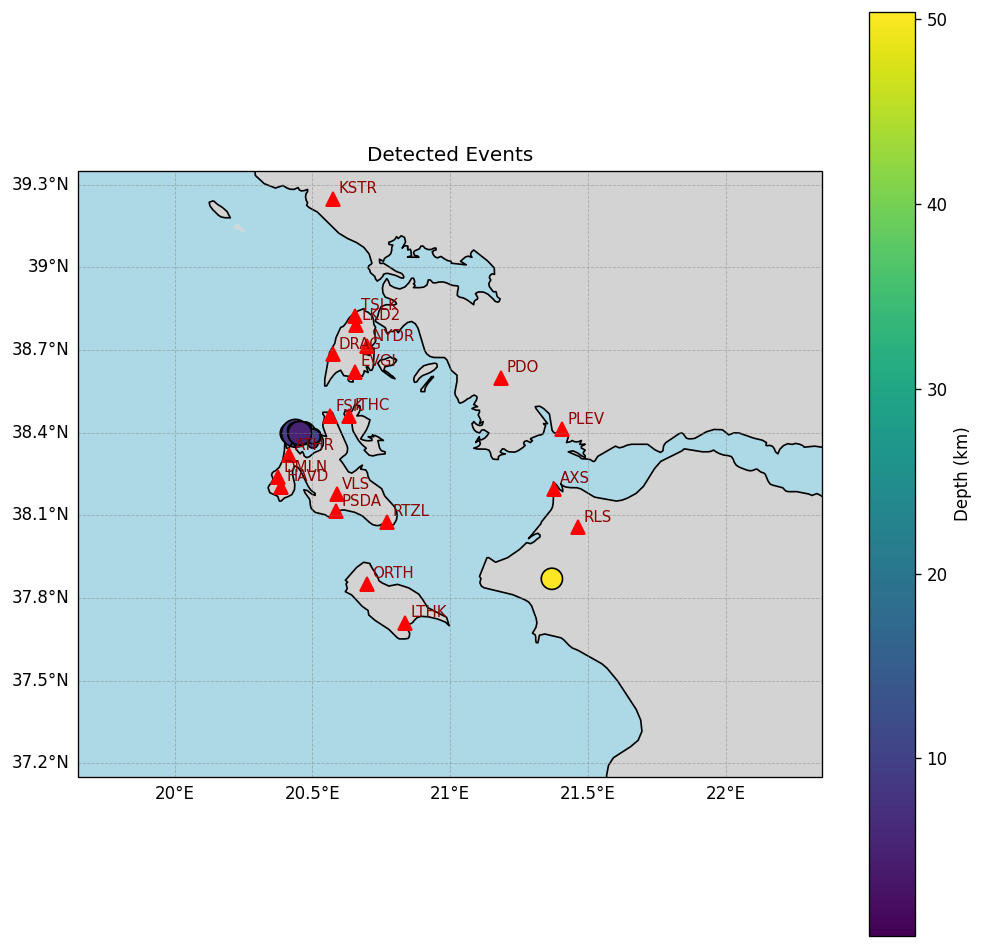

In [ ]:
# ========================
#  Map visualization
# ========================


if SAVE_OUTPUTS:
    os.makedirs(OUTPUT_DIR, exist_ok=True)

if hasattr(events, "__len__") and len(events) > 0:
    fig = plt.figure(figsize=(10, 10))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # Add coastlines and terrain
    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.BORDERS, linestyle=":")
    ax.add_feature(cfeature.LAND, facecolor="lightgray")
    ax.add_feature(cfeature.OCEAN, facecolor="lightblue")

    # Plot stations with labels (if available)
    if inv is not None:
        for network in inv:
            for station in network.stations:
                ax.plot(
                    station.longitude,
                    station.latitude,
                    "^",
                    color="red",
                    markersize=8,
                    transform=ccrs.PlateCarree(),
                )
                ax.text(
                    station.longitude + 0.02,
                    station.latitude + 0.02,
                    station.code,
                    fontsize=9,
                    color="darkred",
                    transform=ccrs.PlateCarree(),
                )
    else:
        print("Warning: Station inventory missing → stations not plotted on the map.")

    # Plot events (marker size scales with Magnitude, color shows depth)
    sizes = 80
    try:
        if hasattr(events, "columns") and ("ML" in events.columns) and events["ML"].notna().any():
            ml = events["ML"].astype(float)
            ml_min = float(np.nanmin(ml.values))
            ml_max = float(np.nanmax(ml.values))
            if np.isfinite(ml_min) and np.isfinite(ml_max) and (ml_max > ml_min):
                norm = (ml - ml_min) / (ml_max - ml_min)
                sizes = 40 + 240 * norm  # points^2
            else:
                sizes = 120
    except Exception:
        sizes = 80

    sc = ax.scatter(
        events.longitude,
        events.latitude,
        c=events.depth,
        cmap="viridis",
        s=sizes,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
    )

    # Map extent based on configured bounds with padding (to show all stations)
    pad = 0.35
    ax.set_extent(
        [LON_BOUNDS[0] - pad, LON_BOUNDS[1] + pad,
         LAT_BOUNDS[0] - pad, LAT_BOUNDS[1] + pad],
        crs=ccrs.PlateCarree(),
    )


    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        color="gray",
        alpha=0.5,
        linestyle="--",
    )
    gl.top_labels = False
    gl.right_labels = False

    plt.colorbar(sc, label="Depth (km)")
    plt.title("Detected Events")

    if SAVE_OUTPUTS:
        out_png = os.path.join(OUTPUT_DIR, "detected_events_map.png")
        fig.savefig(out_png, dpi=200, bbox_inches="tight")
        # Save events table if possible
        out_csv = os.path.join(OUTPUT_DIR, "detected_events.csv")
        try:
            events.to_csv(out_csv, index=False)
        except Exception:
            try:
                import pandas as pd
                pd.DataFrame(events).to_csv(out_csv, index=False)
            except Exception as e:
                print(f"Could not save events CSV: {type(e).__name__}: {e}")
        print(f"Saved outputs to '{OUTPUT_DIR}/'.")

    plt.show()
else:
    print("No events detected in this short demo window (or association was skipped).")

### Picks per station

Histogram of associated picks per station (split by phase when available).

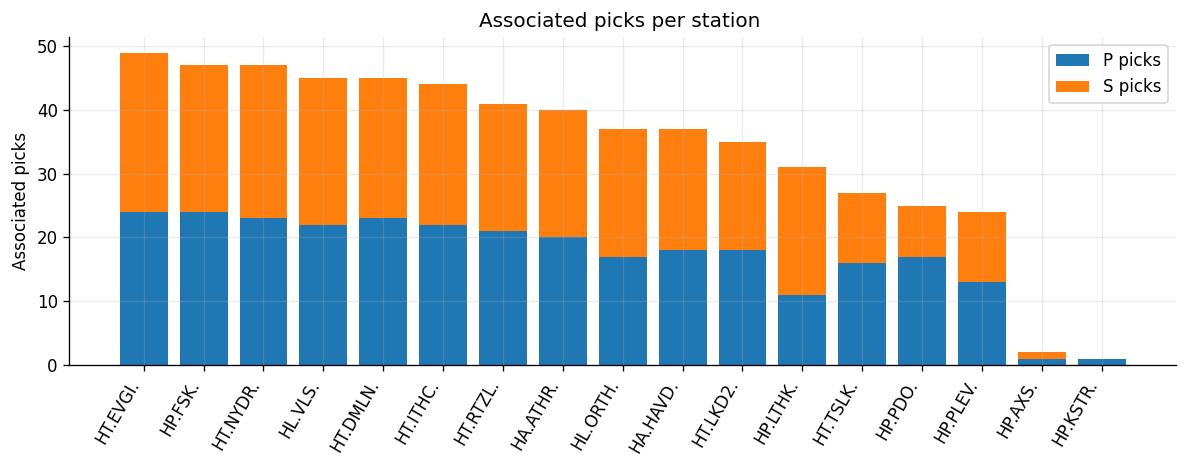

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

if ("station" not in assignments.columns) or (len(assignments) == 0):
    print("No station information available in assignments — cannot plot picks per station.")
else:
    if "phase" in assignments.columns:
        station_phase = assignments.groupby(["station", "phase"]).size().unstack(fill_value=0)

        # ensure columns
        for col in ["P", "S"]:
            if col not in station_phase.columns:
                station_phase[col] = 0

        station_phase = station_phase[["P", "S"]]
        station_phase["total"] = station_phase["P"] + station_phase["S"]
        station_phase = station_phase.sort_values("total", ascending=False)

        fig, ax = plt.subplots(figsize=(10, 4))
        x = np.arrange(len(station_phase))
        ax.bar(x, station_phase["P"].values, label="P picks")
        ax.bar(x, station_phase["S"].values, bottom=station_phase["P"].values, label="S picks")
        ax.set_xticks(x)
        ax.set_xticklabels(station_phase.index.astype(str), rotation=60, ha="right")
        ax.set_ylabel("Associated picks")
        ax.set_title("Associated picks per station ")
        ax.legend()
        plt.tight_layout()
        plt.show()
    else:
        station_counts = assignments.groupby("station").size().sort_values(ascending=False)

        fig, ax = plt.subplots(figsize=(10, 4))
        x = np.arrange(len(station_counts))
        ax.bar(x, station_counts.values)
        ax.set_xticks(x)
        ax.set_xticklabels(station_counts.index.astype(str), rotation=60, ha="right")
        ax.set_ylabel("Associated picks")
        ax.set_title("Associated picks per station")
        plt.tight_layout()
        plt.show()

### Export associated picks to a HypoDD format phase file

The cell below writes a **phase file in HypoDD format** (Waldhauser & Ellsworth, 2000) containing all associated picks.
For this simple example, phase weights are pre-assigned as 1 (best) for P phases and 0.5 for S phases.


In [ ]:
# from obspy import UTCDateTime
# import numpy as np
# import pandas as pd

phase_filename = "phases_hypodd.dat"

if (events is None) or (assignments is None) or len(events) == 0 or len(assignments) == 0:
    print("No events/assignments available — nothing to export.")
else:
    # --- Helper to clean station code for hypoDD (max 5 chars, drop NET.) ---
    def resolve_station_code(sta_val):
        raw = str(sta_val).strip()
        if "." in raw:
            parts = [p for p in raw.split(".") if p]
            if parts:
                code = parts[-1]
            else:
                code = ""
        else:
            code = raw
        if (not code) or code.lower() == "nan":
            return "STA"
        return code[:5]

    # Build event lookup
    ev_lookup = events.set_index("idx")
    lines = []

    for ev_idx, ev in ev_lookup.sort_index().iterrows():
        # All picks that were associated to this event
        ev_ass = assignments[assignments.get("event_idx") == ev_idx]
        if len(ev_ass) == 0:
            continue

        # Origin time from events["time"] (epoch seconds)
        try:
            ot = UTCDateTime(float(ev["time"]))
        except Exception:
            continue

        # Event metadata
        ev_lat = float(ev.get("latitude", np.nan))
        ev_lon = float(ev.get("longitude", np.nan))
        ev_depth = float(ev.get("depth", np.nan)) if pd.notna(ev.get("depth", np.nan)) else 0.0
        mag = float(ev.get("ML", 0.0)) if "ML" in ev and pd.notna(ev["ML"]) else 0.0


        # Numeric event ID for hypoDD
        try:
            evid_int = int(ev_idx)
        except Exception:
            evid_int = len(lines) + 1

        # Seconds field in header
        sec_float = ot.second + ot.microsecond / 1e6

        header = (
            f"# {ot.year:4d}  {ot.month:02d}  {ot.day:02d}"
            f"   {ot.hour:02d}    {ot.minute:02d}"
            f"    {sec_float:6.3f}"
            f"    {ev_lat:8.4f}    {ev_lon:8.4f}"
            f"    {ev_depth:6.2f}"
            f"     {mag:5.3f}"
            f"     0.0     0.0    0.0  {evid_int:d}" #location uncertainties are set to zero
        )
        lines.append(header)

        # Phase lines
        for _, row in ev_ass.iterrows():
            sta_code = resolve_station_code(row.get("station", ""))

            # Phase
            phase = str(row.get("phase", "P")).upper().strip()
            if phase not in ("P", "S"):
                phase = "P"

            # Pick time
            pick_t = row.get("time", None)
            if pick_t is None or (isinstance(pick_t, float) and not np.isfinite(pick_t)):
                continue
            try:
                pick_dt = UTCDateTime(float(pick_t))
            except Exception:
                continue

            dt = pick_dt - ot
            if not np.isfinite(dt):
                continue

            # Weights: 1.0 for P, 0.5 for S
            weight = 1.0 if phase == "P" else 0.5

            line = f"{sta_code:<5s} {dt:7.4f} {weight:4.1f} {phase:s}"
            lines.append(line)

    if not lines:
        print("No valid picks found to export.")
    else:
        with open(phase_filename, "w") as f:
            for ln in lines:
                f.write(ln + "\n")

        print(f"Wrote hypoDD-formatted phase file: {phase_filename}")
        print("You can download it from the Jupyter file browser (left panel) or via File -> Open...")

Wrote hypoDD-formatted phase file: phases_hypodd.dat
You can download it from the Jupyter file browser (left panel) or via File -> Open...


## Acknowledgements

 Seisbench (Woollam et al.,2022) and specifically parts of the notebook examples publicly provided by the Github page of the toolbox (https://github.com/seisbench/seisbench) were re-purposed for this demo, for which we are grateful.
